# 04. Thực nghiệm, đánh giá và phân tích lỗi (tuần 9–10)

Nội dung: đánh giá cuối cùng trên tập kiểm tra, ước lượng bằng kiểm định chéo, tinh chỉnh siêu tham số (C, L1/L2, tốc độ học), chọn ngưỡng quyết định, diễn giải hệ số và phân tích mẫu bị dự đoán sai.

Tương ứng chương 5 của báo cáo. Chỉ tập huấn luyện được dùng để chọn tham số; tập kiểm tra chỉ dùng để báo cáo kết quả cuối.

In [1]:
import os, sys, warnings
from pathlib import Path
root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
from src.models import experiments as ex
from src.models.evaluate import compute_metrics, majority_baseline
from src.models.logistic_regression_scratch import LogisticRegressionScratch
from src.models.logistic_regression_sklearn import build_pipeline, C_GRID
from src.utils import visualization as viz
pd.options.display.float_format = "{:.4f}".format

## 1. Dữ liệu và mô hình cuối

In [2]:
data, q_train, q_test = ex.load_split_with_quality()
feats = data.feature_names
print("train:", data.X_train_raw.shape, "| test:", data.X_test_raw.shape)
print("Mốc đa số (test):", round(majority_baseline(data.y_test), 4))

final = build_pipeline(C=1.0).fit(data.X_train_raw, data.y_train)
p_sk = final.predict_proba(data.X_test_raw)[:, 1]
scratch = LogisticRegressionScratch(lr=0.5, n_iter=20000, lam=1.0).fit(data.X_train, data.y_train)
p_sc = scratch.predict_proba(data.X_test)
res = pd.DataFrame({"scikit-learn": compute_metrics(data.y_test, p_sk),
                    "tự cài đặt": compute_metrics(data.y_test, p_sc)}).T
res

Số mẫu gốc: 1599 | giá trị thiếu: 0 | bản ghi trùng: 240
train: (1087, 11) | test: (272, 11)
Mốc đa số (test): 0.5294


,accuracy,precision,recall,f1,roc_auc,log_loss,TN,FP,FN,TP
scikit-learn,0.7353,0.7609,0.7292,0.7447,0.8116,0.5241,95.0000,33.0000,39.0000,105.0000
tự cài đặt,0.7353,0.7609,0.7292,0.7447,0.8116,0.5241,95.0000,33.0000,39.0000,105.0000


scikit-learn [[95, 33], [39, 105]]
tự cài đặt [[95, 33], [39, 105]]


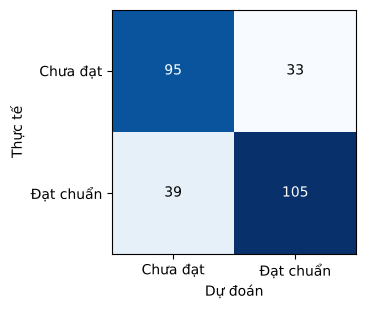

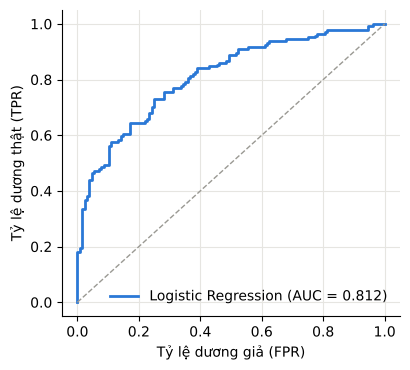

In [3]:
for name, p in (("scikit-learn", p_sk), ("tự cài đặt", p_sc)):
    m = compute_metrics(data.y_test, p)
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    print(name, cm.tolist())
fig = viz.plot_confusion_matrix(np.array([[res.loc['scikit-learn','TN'], res.loc['scikit-learn','FP']],
                                          [res.loc['scikit-learn','FN'], res.loc['scikit-learn','TP']]]))
viz.save(fig, "5_1_confusion_matrix.png"); plt.show()
fig = viz.plot_roc(data.y_test, {"Logistic Regression (AUC = %.3f)" % res.loc['scikit-learn','roc_auc']: p_sk})
viz.save(fig, "5_2_roc.png"); plt.show()

## 2. Ước lượng ổn định bằng kiểm định chéo 5-fold (chỉ trên tập huấn luyện)

In [4]:
cv_tab = ex.cv_estimate(data.X_train_raw, data.y_train, C=1.0)
cv_tab

,mean,std
accuracy,0.7452,0.0438
precision,0.7680,0.0426
recall,0.7426,0.0458
f1,0.7550,0.0428
roc_auc,0.8161,0.0314


## 3. Tinh chỉnh siêu tham số

### 3.1 Hệ số điều chuẩn C, so sánh L2 và L1

,C,penalty,accuracy,acc_std,f1,roc_auc,n_nonzero
0,0.0010,l2,0.7268,0.0373,0.7594,0.8102,11
1,0.0100,l2,0.7323,0.0383,0.7419,0.8161,11
2,0.1000,l2,0.7433,0.0422,0.7520,0.8170,11
3,1.0000,l2,0.7452,0.0438,0.7550,0.8161,11
4,10.0000,l2,0.7443,0.0447,0.7539,0.8160,11
5,100.0000,l2,0.7443,0.0447,0.7539,0.8161,11
6,1000.0000,l2,0.7433,0.0436,0.7528,0.8160,11


,C,penalty,accuracy,acc_std,f1,roc_auc,n_nonzero
0,0.0010,l1,0.4710,0.0013,0.0000,0.5000,0
1,0.0100,l1,0.7028,0.0394,0.6928,0.7846,2
2,0.1000,l1,0.7387,0.0429,0.7405,0.8176,7
3,1.0000,l1,0.7452,0.0435,0.7540,0.8160,11
4,10.0000,l1,0.7461,0.0445,0.7556,0.8160,11
5,100.0000,l1,0.7443,0.0447,0.7539,0.8160,11
6,1000.0000,l1,0.7443,0.0447,0.7539,0.8160,11


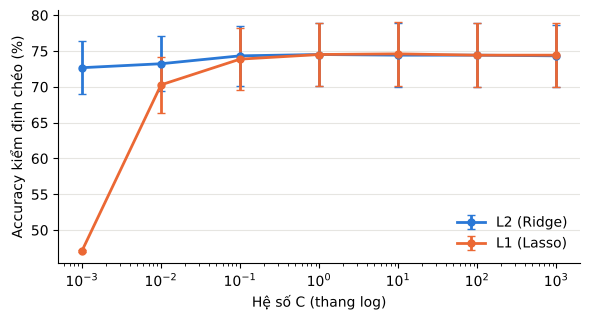

In [5]:
l2 = ex.c_sweep(data.X_train_raw, data.y_train, C_GRID, "l2")
l1 = ex.c_sweep(data.X_train_raw, data.y_train, C_GRID, "l1")
display(l2); display(l1)
fig = viz.plot_c_sweep(l2, l1); viz.save(fig, "5_3_c_sweep.png"); plt.show()

### 3.2 Tốc độ học và hệ số λ của bản tự cài đặt

In [6]:
rows = []
for lr in (0.01, 0.1, 0.5, 1.0, 2.0):
    m = LogisticRegressionScratch(lr=lr, n_iter=20000, lam=1.0).fit(data.X_train, data.y_train)
    rows.append({"lr": lr, "n_iter": len(m.history), "loss": m.history[-1],
                 "test_acc": float((m.predict(data.X_test) == data.y_test).mean())})
lr_tab = pd.DataFrame(rows); display(lr_tab)

rows = []
for lam in (0.001, 0.01, 0.1, 1, 10, 100):
    m = LogisticRegressionScratch(lr=0.5, n_iter=20000, lam=lam).fit(data.X_train, data.y_train)
    rows.append({"lam": lam, "n_iter": len(m.history), "|w|_2": float(np.linalg.norm(m.w)),
                 "train_acc": float((m.predict(data.X_train) == data.y_train).mean())})
lam_tab = pd.DataFrame(rows); lam_tab

,lr,n_iter,loss,test_acc
0,0.0100,20000,0.5141,0.7353
1,0.1000,3675,0.5141,0.7353
2,0.5000,887,0.5141,0.7353
3,1.0000,480,0.5141,0.7353
4,2.0000,262,0.5141,0.7353


,lam,n_iter,|w|_2,train_acc
0,0.0010,966,1.3754,0.7433
1,0.0100,965,1.3753,0.7433
2,0.1000,957,1.3738,0.7433
3,1.0000,887,1.3597,0.7433
4,10.0000,526,1.2494,0.7443
5,100.0000,161,0.8218,0.7378


### 3.3 Đường cong học

,n_train,train,cv,cv_std
0,86,0.7744,0.6983,0.0323
1,198,0.7646,0.7387,0.0480
2,310,0.7503,0.7323,0.0521
3,422,0.7569,0.7350,0.0410
4,533,0.7508,0.7387,0.0468
5,645,0.7464,0.7387,0.0358
6,757,0.7501,0.7406,0.0373
7,869,0.7434,0.7452,0.0438


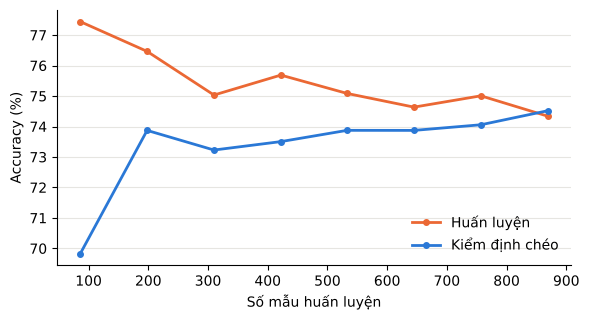

In [7]:
lc = ex.learning_curve_table(data.X_train_raw, data.y_train, C=1.0)
display(lc)
fig = viz.plot_learning_curve(lc); viz.save(fig, "5_4_learning_curve.png"); plt.show()

## 4. Ngưỡng quyết định

Xác suất 'ngoài fold' trên tập huấn luyện được dùng để chọn ngưỡng, tập kiểm tra chỉ dùng để kiểm chứng.

,threshold,accuracy,precision,recall,f1,FP,FN
0,0.3000,0.7176,0.6727,0.9078,0.7728,254,53
1,0.3500,0.7268,0.6931,0.8678,0.7707,221,76
2,0.4000,0.7341,0.7154,0.8261,0.7667,189,100
3,0.4500,0.7470,0.7467,0.7896,0.7675,154,121
4,0.5000,0.7452,0.7680,0.7426,0.7551,129,148
5,0.5500,0.7351,0.7853,0.6870,0.7328,108,180
6,0.6000,0.7332,0.8132,0.6435,0.7184,85,205
7,0.6500,0.7286,0.8333,0.6087,0.7035,70,225
8,0.7000,0.7065,0.8441,0.5461,0.6631,58,261
9,0.7500,0.6891,0.8669,0.4870,0.6236,43,295


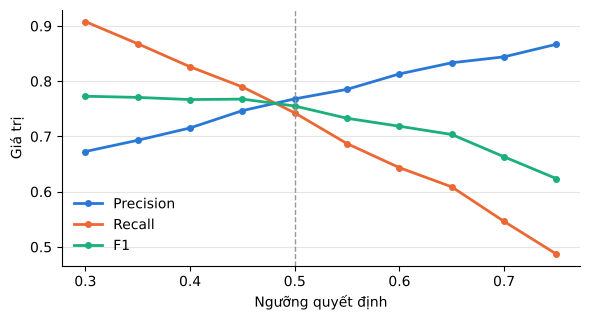

,threshold,accuracy,precision,recall,f1,FP,FN
0,0.3000,0.6912,0.6485,0.9097,0.7572,71,13
1,0.3500,0.7059,0.6739,0.8611,0.7561,60,20
2,0.4000,0.7279,0.7108,0.8194,0.7613,48,26
3,0.4500,0.7243,0.7315,0.7569,0.7440,40,35
4,0.5000,0.7353,0.7609,0.7292,0.7447,33,39
5,0.5500,0.7169,0.7638,0.6736,0.7159,30,47
6,0.6000,0.7206,0.8036,0.6250,0.7031,22,54
7,0.6500,0.7206,0.8542,0.5694,0.6833,14,62
8,0.7000,0.7096,0.8571,0.5417,0.6638,13,66
9,0.7500,0.6875,0.8734,0.4792,0.6188,10,75


In [8]:
p_oof = ex.oof_probabilities(data.X_train_raw, data.y_train, C=1.0)
thr_train = ex.threshold_table(data.y_train, p_oof)
display(thr_train)
fig = viz.plot_threshold(thr_train); viz.save(fig, "5_5_threshold.png"); plt.show()
thr_test = ex.threshold_table(data.y_test, p_sk)
display(thr_test)

## 5. Diễn giải hệ số (bootstrap 1000 lần)

,coef,ci_low,ci_high,odds_ratio,or_low,or_high,significant
alcohol,0.9869,0.7455,1.2804,2.6830,2.1076,3.5981,True
total sulfur dioxide,-0.5178,-0.7774,-0.3032,0.5958,0.4596,0.7385,True
sulphates,0.4770,0.3002,0.7154,1.6112,1.3502,2.0450,True
volatile acidity,-0.4769,-0.7143,-0.2684,0.6207,0.4895,0.7646,True
chlorides,-0.2170,-0.4321,-0.0247,0.8049,0.6492,0.9756,True
fixed acidity,0.1955,-0.2035,0.6185,1.2159,0.8159,1.8561,False
free sulfur dioxide,0.1832,0.0071,0.3678,1.2010,1.0072,1.4445,True
citric acid,-0.1393,-0.4351,0.1072,0.8699,0.6472,1.1131,False
density,-0.0763,-0.4420,0.2637,0.9266,0.6428,1.3017,False
pH,-0.0743,-0.3176,0.1823,0.9284,0.7279,1.2000,False


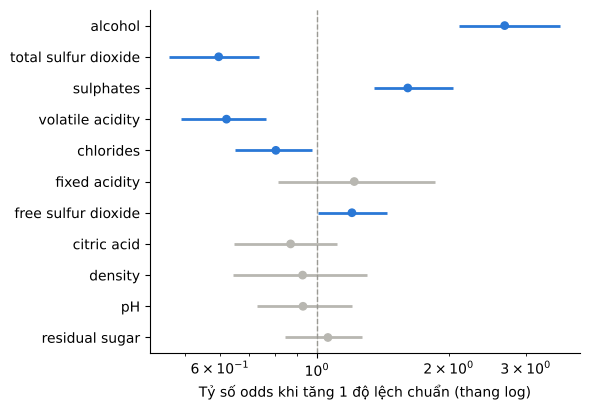

In [9]:
coef = ex.bootstrap_coefficients(data.X_train_raw, data.y_train, C=1.0, n_boot=1000)
display(coef)
fig = viz.plot_odds_ratio(coef); viz.save(fig, "5_6_odds_ratio.png"); plt.show()

## 6. Phân tích lỗi trên tập kiểm tra

{'TP': 105, 'TN': 95, 'FN': 39, 'FP': 33}


,n,n_wrong,error_rate
quality,,,
3,3,1,0.3333
4,13,5,0.3846
5,112,27,0.2411
6,100,39,0.3900
7,38,0,0.0000
8,6,0,0.0000


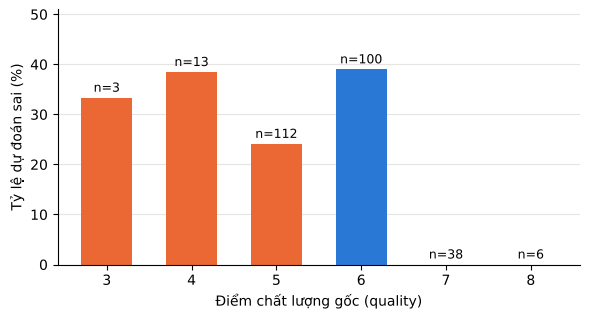

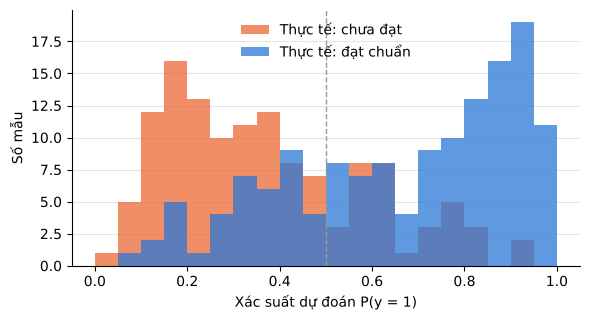

In [10]:
err = ex.build_error_frame(data.X_test_raw, data.y_test, p_sk, q_test)
print(err.outcome.value_counts().to_dict())
by_q = ex.error_by_quality(err); display(by_q)
fig = viz.plot_error_by_quality(by_q); viz.save(fig, "5_7_error_by_quality.png"); plt.show()
fig = viz.plot_proba_hist(err); viz.save(fig, "5_8_proba_hist.png"); plt.show()

In [11]:
border = (err.margin < 0.1)
print("Mẫu có |p - 0.5| < 0.1:", int(border.sum()), "| tỷ lệ sai trong nhóm này:", round(float((err.y_true != err.y_pred)[border].mean()), 4))
print("Tỷ lệ sai ngoài nhóm:", round(float((err.y_true != err.y_pred)[~border].mean()), 4))
prof = ex.error_profile(err, feats, data.scaler); prof

Mẫu có |p - 0.5| < 0.1: 54 | tỷ lệ sai trong nhóm này: 0.4444
Tỷ lệ sai ngoài nhóm: 0.2202


outcome,TP,TN,FP,FN
fixed acidity,0.1324,-0.1547,0.4269,-0.2486
volatile acidity,-0.6058,0.5904,-0.1833,0.0550
citric acid,0.3345,-0.3605,0.2660,-0.3733
residual sugar,-0.1388,-0.1273,0.1020,0.0314
chlorides,-0.2408,0.0769,0.1660,0.1707
free sulfur dioxide,0.0294,0.1490,-0.2754,0.0244
total sulfur dioxide,-0.2805,0.3638,-0.2322,0.1564
density,-0.3622,0.1491,0.2401,0.2708
pH,-0.0105,-0.0810,-0.3477,0.0636
sulphates,0.3314,-0.4076,0.3878,-0.2567


In [12]:
print(err[err.outcome == "FN"].sort_values("proba").head(5)[["quality","proba","alcohol","volatile acidity","sulphates"]])
print(err[err.outcome == "FP"].sort_values("proba", ascending=False).head(5)[["quality","proba","alcohol","volatile acidity","sulphates"]])

      quality  proba  alcohol  volatile acidity  sulphates
1226        6 0.0987   9.6000            0.7850     0.5200
898         6 0.1145   9.1000            0.6400     0.6200
140         6 0.1162   9.3000            0.6000     0.5700
664         6 0.1650   9.7000            0.5900     0.5300
213         6 0.1725   9.8000            0.5800     0.4900
      quality  proba  alcohol  volatile acidity  sulphates
1088        4 0.9126  12.0000            0.4000     0.5600
951         5 0.9076  12.9000            0.6600     0.5800
41          4 0.8360  13.1000            0.5200     0.5600
703         4 0.8099  11.4000            0.3900     0.5800
318         5 0.8046  10.2000            0.4600     0.8700


## 7. Lưu kết quả

In [13]:
out = Path("reports/tables"); out.mkdir(parents=True, exist_ok=True)
res.to_csv(out / "test_metrics.csv"); cv_tab.to_csv(out / "cv_metrics.csv")
l2.to_csv(out / "c_sweep_l2.csv", index=False); l1.to_csv(out / "c_sweep_l1.csv", index=False)
lr_tab.to_csv(out / "scratch_lr.csv", index=False); lam_tab.to_csv(out / "scratch_lambda.csv", index=False)
thr_train.to_csv(out / "threshold_train_oof.csv", index=False); thr_test.to_csv(out / "threshold_test.csv", index=False)
coef.to_csv(out / "coef_bootstrap.csv"); by_q.to_csv(out / "error_by_quality.csv"); prof.to_csv(out / "error_profile.csv")
lc.to_csv(out / "learning_curve.csv", index=False)
err.to_csv(out / "test_predictions.csv")
print("Đã lưu vào", out)

Đã lưu vào reports/tables
